In [1]:
import os
os.makedirs("/tmp/tz", exist_ok=True)
!wget -q --show-progress "https://zenodo.org/records/4314960/files/malaria_dataset.zip?download=1" -O /tmp/tz/tz.zip
!unzip -q /tmp/tz/tz.zip -d /tmp/tz/data
!du -sh /tmp/tz/data

/tmp/tz/tz.zip      100%[===================>] 142.03M   452KB/s    in 5m 24s  
176M	/tmp/tz/data


In [2]:
from pathlib import Path
from collections import Counter
import json

root = Path("/tmp/tz/data")
files = [p for p in root.rglob("*") if p.is_file()]
print("Total files:", len(files))
print("By type:", Counter(p.suffix.lower() for p in files))

for p in sorted(root.iterdir()):
    print(p.name)
    if p.is_dir():
        subs = sorted(p.iterdir())
        for s in subs[:5]: print("   ", s.name)
        print("    ... total", len(subs))

jpgs = sorted(p for p in files if p.suffix.lower() == ".jpg")
print("\nSample image names:", [p.name for p in jpgs[:3]], [p.name for p in jpgs[-3:]])

xml = sorted(p for p in files if p.suffix.lower() == ".xml")
if xml:
    print("\nExample XML:", xml[0]); print(xml[0].read_text()[:900])

for j in [p for p in files if p.suffix.lower() == ".json"]:
    d = json.load(open(j))
    print("\nJSON:", j.name, "| keys:", list(d.keys()) if isinstance(d, dict) else type(d))
    if isinstance(d, dict):
        for k in ["images", "annotations", "categories"]:
            if k in d: print(f"  {k}: {len(d[k])} | first: {d[k][0]}")

Total files: 10908
By type: Counter({'.xml': 5453, '.jpg': 5453, '.json': 1, '.csv': 1})
COCO_mkapa_train
    000001.jpg
    000001.xml
    000002.jpg
    000002.xml
    000003.jpg
    ... total 10908

Sample image names: ['000001.jpg', '000002.jpg', '000003.jpg'] ['005451.jpg', '005452.jpg', '005453.jpg']

Example XML: /tmp/tz/data/COCO_mkapa_train/000001.xml
<annotation>
    <folder>keras-frcnn-master</folder>
    <filename>000001</filename>
    <path>/gdrive/My Drive/Malaria-v2/keras-frcnn-master/000001</path>
    <source>
        <database>Unknown</database>
    </source>
    <size>
        <width>750</width>
        <height>750</height>
        <depth>3</depth>
    </size>
    <segmented>0</segmented>
    <object>
        <name>Plasmodium trophozoites</name>
        <pose>Unspecified</pose>
        <truncated>0</truncated>
        <difficult>0</difficult>
        <bndbox>
            <xmin>697</xmin>
            <ymin>586</ymin>
            <xmax>727</xmax>
            <ymax>619</

In [3]:
import pandas as pd, xml.etree.ElementTree as ET

csv = next(p for p in files if p.suffix.lower() == ".csv")
raw = csv.read_text(errors="replace").splitlines()
print(csv.name, "|", len(raw), "lines")
for line in raw[:6]:
    print(line[:300])
print("Fields per line (first 2,000 lines):", Counter(len(l.split(",")) for l in raw[:2000]).most_common(8))

rows = []
for x in xml:
    r = ET.parse(x).getroot()
    for o in r.findall("object"):
        b = o.find("bndbox")
        rows.append(dict(image=x.stem, name=o.find("name").text.strip(),
                         **{k: float(b.find(k).text) for k in ["xmin", "ymin", "xmax", "ymax"]}))
lab = pd.DataFrame(rows)
lab["w"], lab["h"] = lab.xmax - lab.xmin, lab.ymax - lab.ymin
print("\nXML objects:", len(lab), "\n", lab.name.value_counts())

d = json.load(open(next(p for p in files if p.suffix.lower() == ".json")))
cats = {c["id"]: c["name"] for c in d["categories"]}
print("\nJSON objects:", len(d["annotations"]), "\n", pd.Series([cats[a["category_id"]] for a in d["annotations"]]).value_counts())

print("\nTiles with no objects:", len(xml) - lab.image.nunique(), "of", len(xml))
print("\nMedian box size (px) per class:\n", lab.groupby("name")[["w", "h"]].median())

mapper.csv | 614 lines
old_name,new_names
IMG_2145,000001,000002,000003,000004,000005,000006,000007,000008,000009,000010
IMG_2146,000011,000012,000013,000014,000015,000016,000017,000018,000019,000020,000021,000022,000023
IMG_2148,000024,000025,000026,000027,000028,000029,000030,000031,000032,000033,000034
IMG_2149,000035,000036,000037,000038,000039,000040,000041,000042,000043,000044
IMG_2151,000045,000046,000047,000048,000049,000050,000051,000052,000053,000054,000055,000056,000057
Fields per line (first 2,000 lines): [(12, 80), (13, 79), (11, 60), (14, 60), (7, 60), (10, 43), (8, 43), (9, 39)]

XML objects: 24255 
 name
Plasmodium trophozoite       21130
WBC                           2457
Plasmodium trophozoites        629
plasmodium                      21
Plasimodium trophozoite         16
Plasmodium gametocyte            1
WBCPlasmodium trophozoite        1
Name: count, dtype: int64

JSON objects: 24255 
 Plasmodium trophozoite       21130
WBC                           2457
Plasmodi

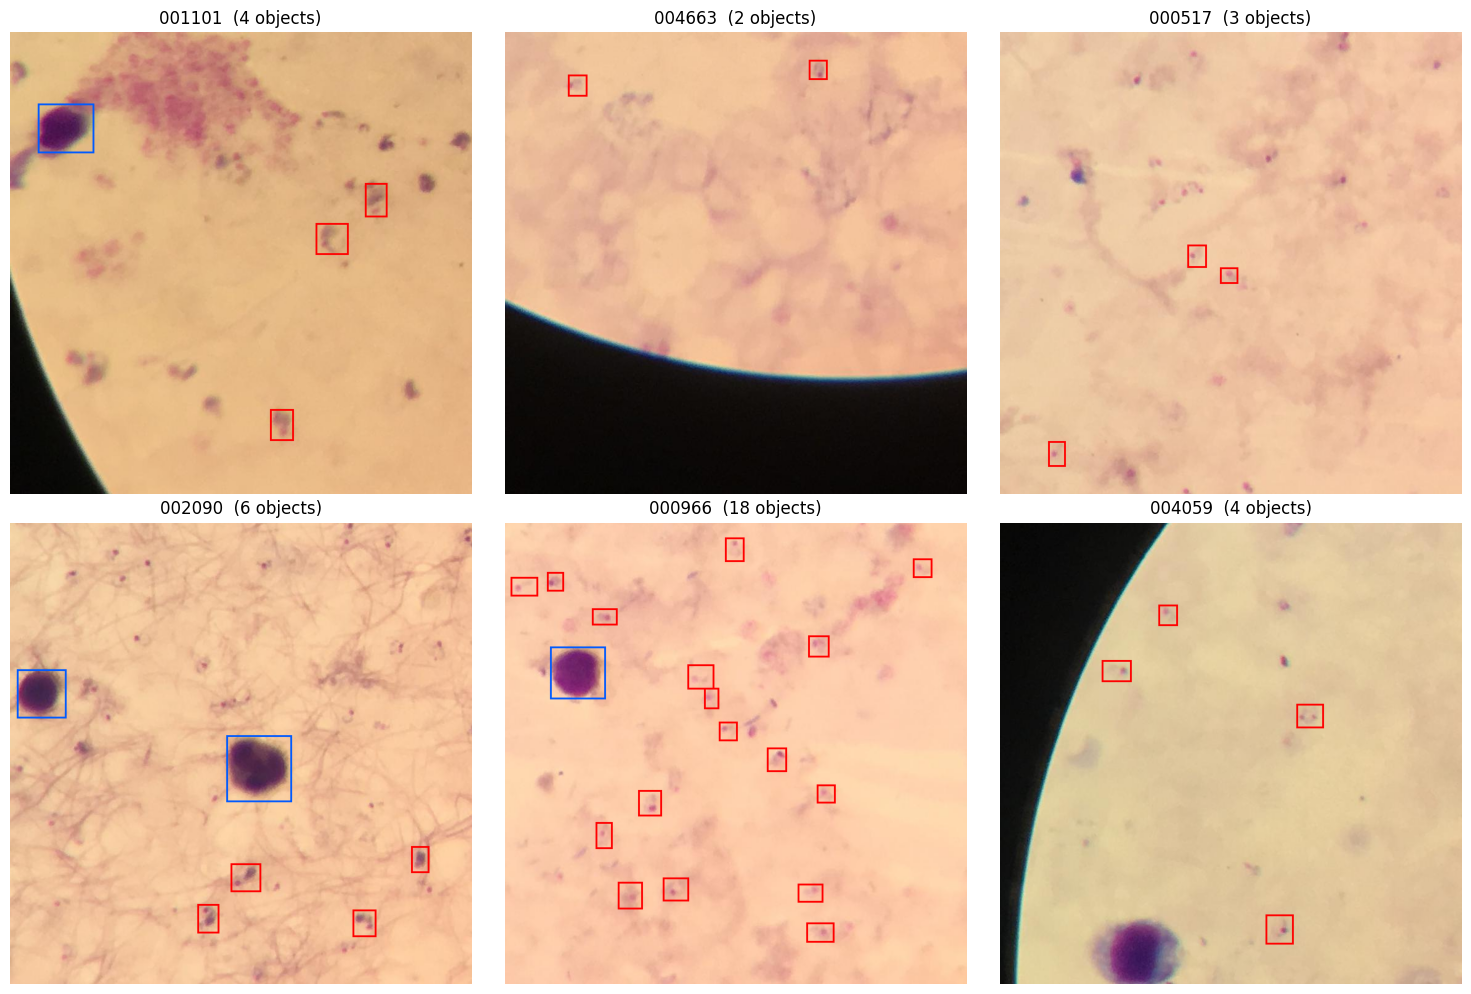

In [4]:
import random, matplotlib.pyplot as plt
from PIL import Image, ImageDraw
random.seed(1)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, stem in zip(axes.flat, random.sample(sorted(lab.image.unique()), 6)):
    im = Image.open(root / "COCO_mkapa_train" / f"{stem}.jpg").convert("RGB"); dr = ImageDraw.Draw(im)
    for _, o in lab[lab.image == stem].iterrows():
        colour = (0, 90, 255) if o["name"].upper().startswith("WBC") and "Plasmodium" not in o["name"] else (255, 0, 0)
        dr.rectangle([o.xmin, o.ymin, o.xmax, o.ymax], outline=colour, width=3)
    ax.imshow(im); ax.set_title(f"{stem}  ({(lab.image == stem).sum()} objects)"); ax.axis("off")
plt.tight_layout(); plt.show()

In [5]:
import numpy as np

pairs = []
for line in raw[1:]:
    parts = [s.strip() for s in line.split(",") if s.strip()]
    pairs += [(t, parts[0]) for t in parts[1:]]
tile2photo = dict(pairs)
lab["photo"] = lab.image.map(tile2photo)
print("Tiles mapped to a photo:", lab.image.map(tile2photo).notna().groupby(lab.image).first().mean().round(3))

lab["cls"] = np.where(lab.name.str.strip() == "WBC", "wbc", "parasite")  
print(lab.cls.value_counts())

per_tile = lab.groupby(["photo", "image", "cls"]).size().unstack(fill_value=0)
per_photo = per_tile.groupby("photo").sum()
per_photo["tiles"] = per_tile.groupby("photo").size()
print("\nPer photo:\n", per_photo.describe().round(1))
print("\nPhotos with zero WBCs labelled:", (per_photo.wbc == 0).sum(), "of", len(per_photo))
print("Tiles with WBCs but no parasites:", ((per_tile.wbc > 0) & (per_tile.parasite == 0)).sum())

Tiles mapped to a photo: 1.0
cls
parasite    21798
wbc          2457
Name: count, dtype: int64

Per photo:
 cls    parasite    wbc  tiles
count     611.0  611.0  611.0
mean       35.7    4.0    8.9
std        36.2    5.0    3.4
min         0.0    0.0    1.0
25%         7.0    2.0    6.0
50%        25.0    3.0   10.0
75%        54.5    5.0   12.0
max       215.0   92.0   15.0

Photos with zero WBCs labelled: 31 of 611
Tiles with WBCs but no parasites: 679


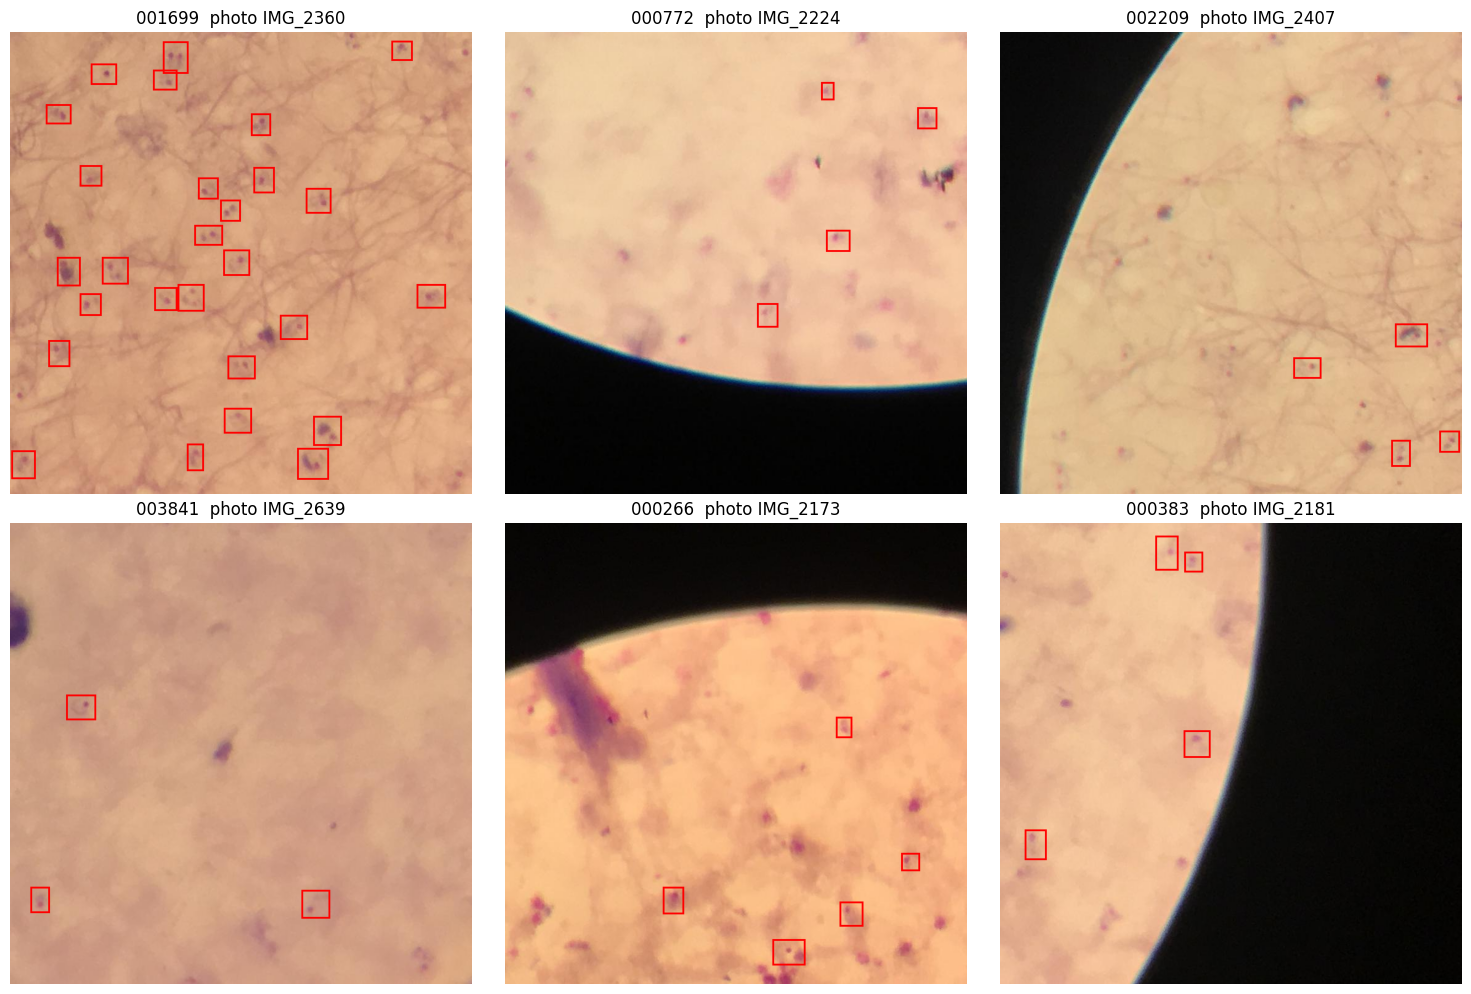

Share of tiles with no WBC labelled: 65.6 %


In [6]:
no_wbc = per_tile[per_tile.wbc == 0].reset_index().image.tolist()
random.seed(7)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, stem in zip(axes.flat, random.sample(no_wbc, 6)):
    im = Image.open(root / "COCO_mkapa_train" / f"{stem}.jpg").convert("RGB"); dr = ImageDraw.Draw(im)
    for _, o in lab[lab.image == stem].iterrows():
        dr.rectangle([o.xmin, o.ymin, o.xmax, o.ymax], outline=(255, 0, 0), width=3)
    ax.imshow(im); ax.set_title(f"{stem}  photo {tile2photo[stem]}"); ax.axis("off")
plt.tight_layout(); plt.show()
print("Share of tiles with no WBC labelled:", round(len(no_wbc) / len(per_tile) * 100, 1), "%")

In [7]:
import numpy as np
bd_parasite = 24.8  
tz_parasite = lab.loc[lab.cls == "parasite", ["w", "h"]].mean(axis=1).median()
S = bd_parasite / tz_parasite
print("Tanzania median parasite box:", tz_parasite, "px  -> scale factor", round(S, 3))
print("WBC box after scaling:", round(lab.loc[lab.cls == "wbc", ["w", "h"]].mean(axis=1).median() * S, 1),
      "px (our Bangladesh WBC boxes: 60)")

pooled = per_photo.parasite.sum() / per_photo.wbc.sum()
print("Pooled parasites per WBC:", round(pooled, 2), "->", round(pooled * 8000), "parasites/uL (whole dataset)")
lab.to_csv("/kaggle/working/tz_labels.csv", index=False)
per_photo.to_csv("/kaggle/working/tz_per_photo.csv")

Tanzania median parasite box: 37.5 px  -> scale factor 0.661
WBC box after scaling: 69.4 px (our Bangladesh WBC boxes: 60)
Pooled parasites per WBC: 8.87 -> 70974 parasites/uL (whole dataset)


In [8]:
import yaml
OUT = Path("/kaggle/working/tz_tiles"); T = 640
for sub in ["images", "labels"]:
    (OUT / "test" / sub).mkdir(parents=True, exist_ok=True)

for stem, a in lab.groupby("image"):
    im = Image.open(root / "COCO_mkapa_train" / f"{stem}.jpg").convert("RGB")
    im = im.resize((round(im.width * S), round(im.height * S)), Image.BILINEAR)
    canvas = Image.new("RGB", (T, T), (0, 0, 0)); canvas.paste(im, (0, 0))
    canvas.save(OUT / "test" / "images" / f"{stem}.jpg", quality=92)
    lines = [f"{0 if c == 'parasite' else 1} {(x1 + x2) / 2 * S / T:.6f} {(y1 + y2) / 2 * S / T:.6f} "
             f"{(x2 - x1) * S / T:.6f} {(y2 - y1) * S / T:.6f}"
             for c, x1, y1, x2, y2 in a[["cls", "xmin", "ymin", "xmax", "ymax"]].itertuples(index=False)]
    (OUT / "test" / "labels" / f"{stem}.txt").write_text("\n".join(lines))

yaml.safe_dump({"path": str(OUT), "train": "test/images", "val": "test/images", "test": "test/images",
                "names": {0: "parasite", 1: "wbc"}}, open(OUT / "data.yaml", "w"))
print("Tanzania test tiles:", len(list((OUT / "test" / "images").glob("*.jpg"))))
!du -sh /kaggle/working/tz_tiles

Tanzania test tiles: 5453
190M	/kaggle/working/tz_tiles
